## 🏗️ Mini Project — Polynomial Regression

#### "Salary Growth Curve Predictor"

- Create a synthetic dataset: experience_years vs salary with a curved relationship (e.g. salary = 30000 + 2000*exp + 500*exp²)
- Loop over degree = 1 to 8 to find the best degree
- Plot train and test MSE against degree (x-axis: degree, y-axis: error), with both lines on one plot
- Identify the best degree and train the final model with it
- Visualise the predictions: scatter plot plus the fitted curve

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)

num_employees = 25

# Generate random data for employees experience and salary
experience = np.random.randint(1, 21, size=num_employees)  # Experience in years
salary = 30000 + 2000 * experience + 500 * experience**2 + np.random.normal(0, 10000, size=num_employees)  # Salary in dollars

salary = np.round(salary, 2)  # Round salary to 2 decimal places

# Create a DataFrame
df = pd.DataFrame({
    'Experience': experience,
    'Salary': salary
})


# Display the DataFrame
df.head()

,Experience,Salary
0,7,69924.65
1,20,269653.48
2,15,183843.39
3,11,111452.54
4,8,72748.77


In [ ]:
# convert into 2D array
X = df['Experience'].values.reshape(-1, 1)

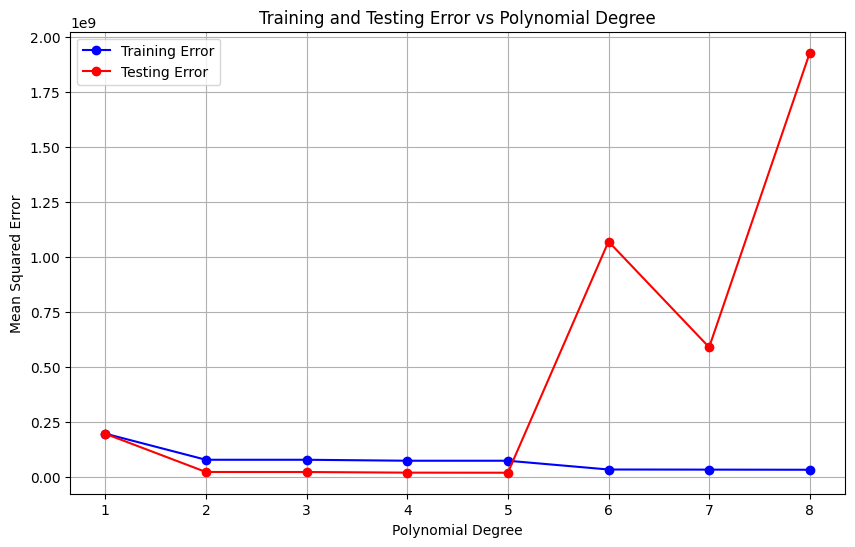

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

# Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(df[['Experience']], df['Salary'], test_size=0.2, random_state=42)

train_error = []
test_error = []
degrees = range(1, 9)  # Degrees from 1 to 8

for d in degrees:
    poly = PolynomialFeatures(degree=d)
    X_train_poly = poly.fit_transform(X_train)
    X_test_poly = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X_train_poly, y_train)

    train_pred = model.predict(X_train_poly)
    test_pred = model.predict(X_test_poly)

    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    train_error.append(train_mse)
    test_error.append(test_mse)

# Plotting the training and testing errors
plt.figure(figsize=(10, 6))
plt.plot(degrees, train_error, marker='o', label='Training Error', color='blue')
plt.plot(degrees, test_error, marker='o', label='Testing Error', color='red')
plt.title('Training and Testing Error vs Polynomial Degree')
plt.xlabel('Polynomial Degree')
plt.ylabel('Mean Squared Error')
plt.legend()
plt.grid(True)
plt.show()


From the above plot we can see the degree is 5 which has less train and test MSE.

Best Polynomial Degree: 5
Training Error: 73736312.97149776
Testing Error: 19257065.42002485


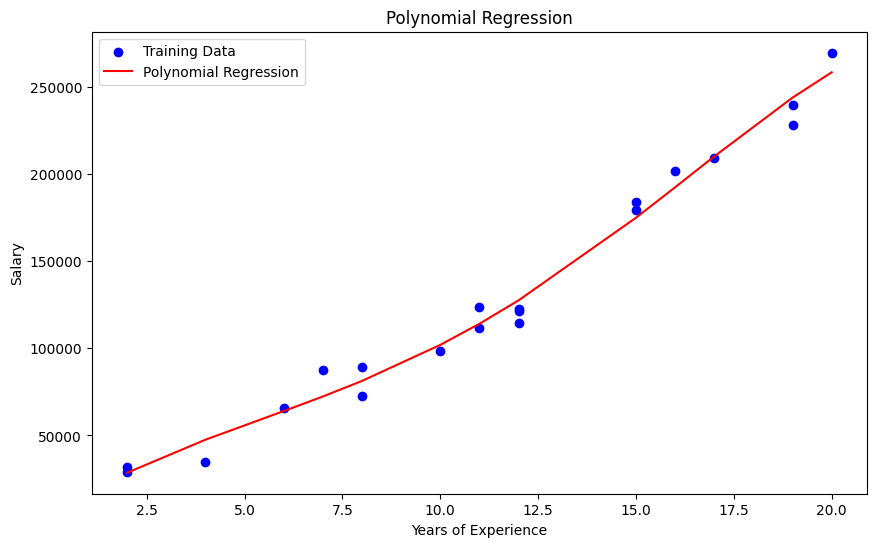

In [ ]:
# Train model with the best degree (the one with the lowest testing error)
best_degree = degrees[np.argmin(test_error)]

poly = PolynomialFeatures(degree=best_degree)

X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

model = LinearRegression()
model.fit(X_train_poly, y_train)

train_pred = model.predict(X_train_poly)
test_pred = model.predict(X_test_poly)

train_mse = mean_squared_error(y_train, train_pred)
test_mse = mean_squared_error(y_test, test_pred)


print(f"Best Polynomial Degree: {best_degree}")
print(f"Training Error: {train_mse}")
print(f"Testing Error: {test_mse}")

# Plotting the polynomial regression curve
plt.figure(figsize=(10, 6))

# Sort by X_train so the line is drawn smoothly
sort_idx = X_train.values.flatten().argsort() if hasattr(X_train, 'values') else X_train.flatten().argsort()
X_sorted = X_train.values[sort_idx] if hasattr(X_train, 'values') else X_train[sort_idx]
pred_sorted = train_pred[sort_idx]

plt.scatter(X_train, y_train, color='blue', label='Training Data')
plt.plot(X_sorted, pred_sorted, color='red', label='Polynomial Regression')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.title('Polynomial Regression')
plt.legend()
plt.show()
